# Symbolic regression for chiral assembly

Can one short, unit-consistent equation predict strong chiral assembly (|g| ≥ 10⁻³), and how does it compare with the random forest of `Figure4.ipynb`? Run the cells in order; all paths are repository-relative.

In [1]:
import pandas as pd

from chiral_sr.data import find_repository_root

pd.set_option('display.max_columns', 20)

DATA_FILE = find_repository_root() / 'data_analysis' / 'data' / 'analysis_data.xlsx'
features = pd.read_excel(DATA_FILE, sheet_name='Exp_ML_features')
metadata = pd.read_excel(DATA_FILE, sheet_name='Exp_ML_metadata')

print(f'Exp_ML_features: {features.shape[0]} rows x {features.shape[1]} columns')
print(f'Exp_ML_metadata: {metadata.shape[0]} rows x {metadata.shape[1]} columns')
display(metadata.head())
display(features.head())

Exp_ML_features: 773 rows x 78 columns
Exp_ML_metadata: 773 rows x 10 columns


,experiment_id,dataset_split,abs_g_factor,family,polymer,solvent,assembly_type,temperature_C,concentration_mg_mL,source_record
0,EXP0001,initial,0.0002,Thiophene family,g42T-TT,Chloroform,c,25,50,2
1,EXP0002,initial,0.0100,Thiophene family,g42T-TT,Chloroform,c,25,100,3
2,EXP0003,initial,0.0070,Thiophene family,g42T-TT,Chloroform,c,25,100,4
3,EXP0004,initial,0.0150,Thiophene family,g42T-TT,Chloroform,c,25,200,5
4,EXP0005,initial,0.0200,Thiophene family,g42T-TT,Chloroform,c,25,300,6


,experiment_id,MW_Mn,MW_Mw,PDI,MolWt_monomer,Temperature,R_atoms_C,R_atom_all,R_bond_1,R_bond_2,...,family_PE/ProDOT family,family_PTQ family,family_PII family,family_NDI family,family_PM7 family,family_DPP family,family_TPT family,family_IDT family,family_polyfluorene family,family_ladder family
0,EXP0001,28000,41000,1.464286,714.946,298.15,1.285714,1.555556,3.714286,8.666667,...,0,0,0,0,0,0,0,0,0,0
1,EXP0002,28000,41000,1.464286,714.946,298.15,1.285714,1.555556,3.714286,8.666667,...,0,0,0,0,0,0,0,0,0,0
2,EXP0003,28000,41000,1.464286,714.946,298.15,1.285714,1.555556,3.714286,8.666667,...,0,0,0,0,0,0,0,0,0,0
3,EXP0004,28000,41000,1.464286,714.946,298.15,1.285714,1.555556,3.714286,8.666667,...,0,0,0,0,0,0,0,0,0,0
4,EXP0005,28000,41000,1.464286,714.946,298.15,1.285714,1.555556,3.714286,8.666667,...,0,0,0,0,0,0,0,0,0,0


## 1. Label and inputs

A row is **strong** when |g| ≥ 10⁻³, as in `Figure4.ipynb`. The equations are built from 15 of the 77 features: the conditions, chain length, side-chain and backbone counts, solvent descriptors and FASTSOLV solubilities. Counts are per repeat unit divided by the repeat-unit mass (the `_Norm_MolWt` columns), so their unit is mol/kg. Every input has a physical unit, and the search rejects any term that adds or subtracts quantities of different units.

In [2]:
from chiral_sr import data

d = data.load()
print(f'{len(d.y)} rows: {d.y.sum()} strong (|g| >= 1e-3), {len(d.y) - d.y.sum()} not strong')
print(f"{len(d.rows['717'])} initial rows, {len(d.rows['56'])} additional rows")
print(f'{len(set(d.groups))} polymer-solvent pairs (the cross-validation groups), '
      f'{len(set(d.chem))} chemistries (one repeat unit, molecular-weight variants together)')

inputs = pd.DataFrame({'short name': [data.SHORT[c] for c in d.X.columns],
                       'values in': [data.VALUE_UNITS.get(c, 'mol/kg') for c in d.X.columns],
                       'dimension (search)': d.units,
                       'description': [data.DESCRIPTIONS[c] for c in d.X.columns]},
                      index=pd.Index(d.X.columns, name='input'))
display(inputs)
display(d.X.describe().T[['mean', 'min', '50%', 'max']].round(3))

773 rows: 271 strong (|g| >= 1e-3), 502 not strong
717 initial rows, 56 additional rows
214 polymer-solvent pairs (the cross-validation groups), 59 chemistries (one repeat unit, molecular-weight variants together)


,short name,values in,dimension (search),description
input,,,,
Temperature,T,K,K,condition: temperature
Concentration_mg_mL,c,mg/mL,kg/m**3,condition: polymer concentration
MW_Mn,Mn,g/mol,kg/mol,chain length: number-average molecular weight
SC_C_atoms,SC_C,mol/kg,mol/kg,side chain: carbon atoms
SC_O_atoms,SC_O,mol/kg,mol/kg,side chain: oxygen atoms (glycol / alkoxy)
SC_n_units,SC_units,mol/kg,mol/kg,side chain: side chains (grafting density)
SC_n_branch_points,SC_branch,mol/kg,mol/kg,side chain: branch points
BB_C_atoms,BB_C,mol/kg,mol/kg,backbone: carbon atoms
BB_hetero_atoms,BB_hetero,mol/kg,mol/kg,backbone: heteroatoms


,mean,min,50%,max
Temperature,306.708,298.150,298.150,463.150
Concentration_mg_mL,165.724,10.000,200.000,300.000
MW_Mn,30542.744,3600.000,23800.000,177000.000
SC_C_atoms,33.348,0.000,36.082,50.676
SC_O_atoms,5.621,0.000,0.000,19.680
SC_n_units,2.634,0.000,2.029,7.451
SC_n_branch_points,1.099,0.000,1.713,3.193
BB_C_atoms,22.221,9.840,22.198,62.442
BB_hetero_atoms,7.019,2.460,6.381,17.948
BB_conjugated_units,3.645,1.140,3.559,6.014


## 2. SyMANTIC on the 717 initial rows

The search builds candidate terms from the 15 inputs with + − × ÷, up to two levels deep (e.g. `(SC_C − BB_C)·(c·SC_branch)`), keeping only unit-consistent terms. It then selects the best combinations of 1 to 5 terms for a logistic model (ridge 0.1 on the standardised coefficients; Pareto selection 'utopia', seed 7). The result is a Pareto front of accuracy against complexity; the law reported is the lowest-loss model with 5 terms.

The 56 additional rows are left out here, so they can test the structure later (section 4).

In [3]:
from chiral_sr import laws, search

rows717 = d.rows['717']
front = search.search(d, rows717, operators='binary')
best_per_k = front.loc[front.groupby('n_terms').log_loss.idxmin()]
print(f'{len(front)} models on the Pareto front; the lowest-loss model for each number of terms:')
with pd.option_context('display.max_colwidth', None):
    display(best_per_k.assign(equation=best_per_k.equation.map(data.short)).set_index('n_terms').round(3))

terms = search.terms(search.best(front, k=5)['equation'])
F = laws.term_values(terms, d.X)
fit717 = laws.fit(F, d.y, rows717, terms)
print('Same terms as b37 in chiral_sr/laws.py:', terms == laws.LAWS['b37']['terms'])
print(fit717.equation())
display(pd.DataFrame({'term': [data.short(t) for t in terms],
                      'effect (logit per SD)': fit717.effects.round(2)}, index=[f'T{k + 1}' for k in range(len(terms))]))

38 models on the Pareto front; the lowest-loss model for each number of terms:


,complexity,log_loss,equation
n_terms,,,
0,0.000,0.653,logit P(1) = -0.576091
1,4.755,0.544,logit P(1) = 0.0286458·(SC_C·SC_branch) + -1.94235
2,5.755,0.535,logit P(1) = 0.957437·SC_branch + -0.122666·(SC_units·BB_hetero) + 0.125013
3,45.958,0.468,logit P(1) = 0.000283872·((SC_C-BB_C)·(c·SC_branch)) + 0.188841·((HBA-F_mono)·(SC_units·F_mono)) + -0.301382·(SC_units+(SC_branch·F_mono)) + 0.259773
4,64.602,0.425,logit P(1) = 0.00113047·((SC_C-BB_C)·(c·SC_branch)) + 0.197001·((HBA-F_mono)·(SC_units·F_mono)) + -1.4373e-06·((c·SC_C)·(c·SC_branch)) + -3.61815e-08·((c·Mn)·(logP·F_mono)) + -0.725864
5,82.696,0.390,logit P(1) = 0.00137103·((SC_C-BB_C)·(c·SC_branch)) + 0.21657·((HBA-F_mono)·(SC_units·F_mono)) + -8.79957e-08·((HBA+F_mono)·(c·Mn)) + -1.74656e-06·((c·SC_C)·(c·SC_branch)) + -0.00190783·((SC_C-BB_C)·(SC_units·BB_C)) + 0.395724


Same terms as b37 in chiral_sr/laws.py: True
logit P = +0.001371·((SC_C-BB_C)·(c·SC_branch)) +0.2166·((HBA-F_mono)·(SC_units·F_mono)) -8.8e-08·((HBA+F_mono)·(c·Mn)) -1.747e-06·((c·SC_C)·(c·SC_branch)) -0.001908·((SC_C-BB_C)·(SC_units·BB_C)) +0.3957


,term,effect (logit per SD)
T1,((SC_C-BB_C)·(c·SC_branch)),4.10
T2,((HBA-F_mono)·(SC_units·F_mono)),1.25
T3,((HBA+F_mono)·(c·Mn)),-0.86
T4,((c·SC_C)·(c·SC_branch)),-2.77
T5,((SC_C-BB_C)·(SC_units·BB_C)),-0.94


**The equation found on the 717 rows**, with the coefficients printed above:

$$
\begin{aligned}
\operatorname{logit} P \;=\;& 1.371\times10^{-3}\,(\mathrm{SC_C}-\mathrm{BB_C})\;c\;\mathrm{SC_{branch}}
\;+\; 0.2166\,(\mathrm{HBA}-F_{\mathrm{mono}})\;\mathrm{SC_{units}}\;F_{\mathrm{mono}} \\
&-\; 8.800\times10^{-8}\,(\mathrm{HBA}+F_{\mathrm{mono}})\;c\;M_n
\;-\; 1.747\times10^{-6}\;c^{2}\;\mathrm{SC_C}\;\mathrm{SC_{branch}} \\
&-\; 1.908\times10^{-3}\,(\mathrm{SC_C}-\mathrm{BB_C})\;\mathrm{SC_{units}}\;\mathrm{BB_C}
\;+\; 0.3957
\end{aligned}
$$

The quantities and their units:
- P is the probability of strong chiral assembly (|g| ≥ 10⁻³), with P = 1 / (1 + e^(−logit P)).
- c is the concentration in mg/mL, and Mₙ the number-average molecular weight in g/mol.
- SC_C, SC_branch, SC_units and BB_C are side-chain and backbone counts per repeat unit divided by the repeat-unit mass, in mol per kg of polymer.
- HBA is the solvent's number of H-bond acceptors.
- F_mono is the FASTSOLV solubility of the repeat unit in the solvent, in log₁₀ mol/L.

The five terms, in order, are T1 to T5 of the table above.

## 3. Head to head with the random forest on the authors' protocol

The protocol is the one in `Figure4.ipynb`, run on the 717 initial rows:
- 20 repeats of `StratifiedGroupKFold(5, shuffle=True, random_state=1000 + repeat)`, grouped by polymer ‖ solvent;
- AP of the pooled out-of-fold scores of each repeat.

Both models get identical folds:
- **SyMANTIC** uses the 15 inputs. The structure found above is fixed, and its 5 coefficients and intercept are refit on each training fold.
- **The random forest** uses the 41 features, the published hyperparameters and seed `(1000 + repeat) * 100 + fold`, as in `Figure4.ipynb`.

The difference in AP is paired repeat by repeat. Its 95% interval resamples whole chemistries, because rows of one chemistry are not independent.

**Caveat:** the equation's structure was chosen on all 717 rows, so here only its coefficients are fitted inside each fold. The random forest learns everything inside each fold. This comparison therefore favours the equation. The test that does not is the 56 additional rows (section 4).

In [4]:
from chiral_sr import protocol

def symantic_model(train, test, seed):
    return laws.fit(F, d.y, train, terms).logit(F[test])

sr_cv = protocol.authors_cv(d, rows717, symantic_model)
rf_cv = protocol.authors_cv(d, rows717, protocol.random_forest(d))
sr_ap, rf_ap = protocol.ap_per_repeat(d, sr_cv, rows717), protocol.ap_per_repeat(d, rf_cv, rows717)

display(pd.DataFrame({'inputs': ['15 (5-term equation)', '41 features'],
                      'AP mean': [sr_ap.mean(), rf_ap.mean()], 'AP SD': [sr_ap.std(), rf_ap.std()],
                      'AP min': [sr_ap.min(), rf_ap.min()], 'AP max': [sr_ap.max(), rf_ap.max()]},
                     index=['SyMANTIC', 'Random forest']).round(3))
delta = protocol.paired_delta_cv(d, sr_cv, rf_cv, rows717)
print(f"SyMANTIC - random forest: {delta['delta']:+.3f} AP, 95% CI [{delta['ci'][0]:+.3f}, {delta['ci'][1]:+.3f}], "
      f"SyMANTIC higher in {delta['wins']} of {len(sr_cv)} repeats (random ranking: AP {d.y[rows717].mean():.3f})")

,inputs,AP mean,AP SD,AP min,AP max
SyMANTIC,15 (5-term equation),0.789,0.007,0.777,0.801
Random forest,41 features,0.781,0.019,0.729,0.810


SyMANTIC - random forest: +0.008 AP, 95% CI [-0.048, +0.125], SyMANTIC higher in 13 of 20 repeats (random ranking: AP 0.360)


## 4. The law plane

The equation's logit is a sum: intercept + T1 + … + T5, where each term contributes its coefficient times the standardised term. The plot splits that sum by whether a term contains the concentration c:

- **x, the concentration part**, is the sum of the terms with c: T1, T3 and T4. It changes when only the concentration changes.
- **y, the pair part**, is the intercept plus the terms without c: T2 and T5. It depends only on the polymer, the solvent and (through FASTSOLV) the temperature. It is therefore fixed for one polymer–solvent pair at one temperature.

Why split it this way:
- **The picture is exact, not a projection.** The logit equals x + y, so P = 0.5 exactly on the line x + y = 0 (solid). The dashed lines are P = 0.25 (lower left) and P = 0.75 (upper right), i.e. x + y = ∓ ln 3. Rows above and to the right of the solid line are predicted strong.
- **It separates the two questions an experimentalist asks.** A concentration series of one pair at one temperature lies on a horizontal line, and changing c only slides it sideways. A pair's height (y) says whether that polymer in that solvent can become strong. Its position along x says at which concentration.

Each point is one of the 717 rows, scored by the equation fitted in section 2, and coloured by its measured label.

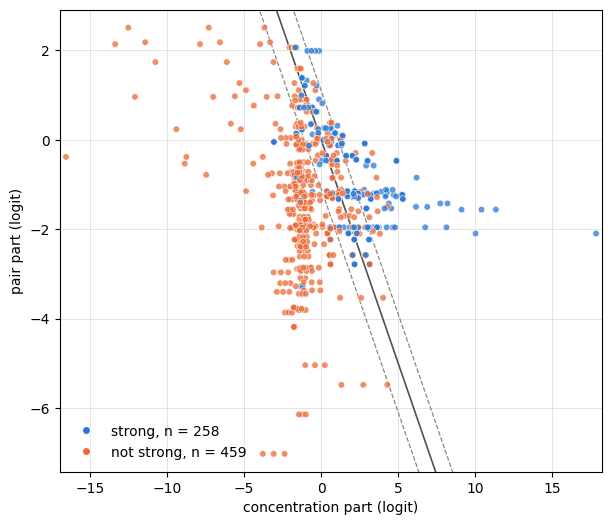

In [5]:
import matplotlib.pyplot as plt

from chiral_sr import plots

x, pair = laws.law_plane(fit717, F[rows717])
fig, ax = plt.subplots(figsize=(7, 6))
plots.law_plane(ax, x, pair, d.y[rows717])
plt.show()

### Reading the equation (semi-quantitative)

The effects quoted below are the logit change per SD of each term, from section 2. Terms that share factors are correlated (T1 with T4: r = 0.76), so they are read in pairs rather than one coefficient at a time. These are associations in this dataset, not mechanisms.

- **T1 and T4: side chains × concentration (+4.10 and −2.77).**
  - Together they equal c·SC_branch·[0.00137·(SC_C − BB_C) − 1.75·10⁻⁶·c·SC_C].
  - Both vanish for unbranched side chains, which is 42% of the rows.
  - For branched side chains with more carbon than the backbone (87% of rows have SC_C > BB_C), they raise P as the concentration rises. The c² part then caps the gain.
  - For a typical polymer (SC_C ≈ 39, BB_C ≈ 22 mol/kg), the effect peaks near 175 mg/mL. For polymers whose side chains carry little more carbon than the backbone, it peaks at lower concentration.
  - In words: strong chiral assembly here is a concentration-driven effect of branched, carbon-rich side chains, with a preferred concentration window.
- **T5: polymer baseline (−0.94).** (SC_C − BB_C)·SC_units·BB_C has no concentration and no solvent in it. Polymers with many carbon-rich side chains start lower. Combined with T1, side chains work in opposite directions: they lower P in dilute solution and, if branched, raise it as the concentration increases.
- **T2: solubility of the repeat unit (+1.25).** (HBA − F_mono)·SC_units·F_mono. The FASTSOLV solubility F_mono (log₁₀ mol/L) is negative for 99% of rows, so T2 is negative. It is most negative for poorly soluble repeat units, in solvents with H-bond acceptors, and for polymers with many side chains. Poor solubility lowers P.
- **T3: chain length × concentration (−0.86).** (HBA + F_mono)·c·Mn.
  - In solvents without H-bond acceptors, HBA + F_mono = F_mono < 0, so long chains at high concentration raise P.
  - In acceptor solvents the bracket is positive for half of the rows, and the same term lowers P there.
  - Read with T2: low solubility generally hurts, but less so for long chains at high concentration in non-acceptor solvents.

## 5. Test on the 56 additional rows

Both models are trained on the 717 initial rows only and scored on the 56 additional rows, in the order the data were collected. This is the test that does not favour the equation: its structure (section 2) never saw these rows.

- **SyMANTIC** is the equation of section 2, fitted on the 717 rows.
- **The random forest** uses the 41 features and the published hyperparameters. Its predicted probability is averaged over 20 forests (seeds 0–19) trained on the 717 rows, so that no single seed decides the result.

What the 56 rows are:
- 13 strong rows, from 6 polymers;
- 10 polymers, all of which also occur in the 717 rows;
- 32 polymer–solvent pairs, none of which occur in the 717 rows;
- P3HT makes up 24 of the rows, all not strong.

So the test asks how well each model handles known polymers in new solvents. With 13 positives the intervals are wide. They come from resampling the 32 test pairs (2,000 resamples). The difference between the models uses the same resamples, so it is paired.

In [6]:
import numpy as np

test = d.rows['56']
probability = {'SyMANTIC': np.full(len(d.y), np.nan), 'Random forest': np.full(len(d.y), np.nan)}
probability['SyMANTIC'][test] = fit717.probability(F[test])
probability['Random forest'][test] = protocol.rf_seed_average(d, rows717, test)

table, draws_ap = protocol.holdout_table(d, probability, test, d.groups[test])
display(table)
delta, ci = protocol.paired_difference(d, probability, draws_ap, test, 'SyMANTIC', 'Random forest')
print(f'SyMANTIC - random forest: {delta:+.3f} AP, 95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}] '
      f'(random ranking: AP {d.y[test].mean():.3f})')

,AP,AP 95% CI,AUC,AUC 95% CI,strong rows caught (P > 0.5),not-strong rows called strong,accuracy
SyMANTIC,0.425,"[0.251, 0.718]",0.753,"[0.575, 0.896]",7 of 13,8 of 43,0.75
Random forest,0.754,"[0.483, 1.000]",0.911,"[0.772, 1.000]",7 of 13,3 of 43,0.839


SyMANTIC - random forest: -0.329 AP, 95% CI [-0.627, -0.016] (random ranking: AP 0.232)


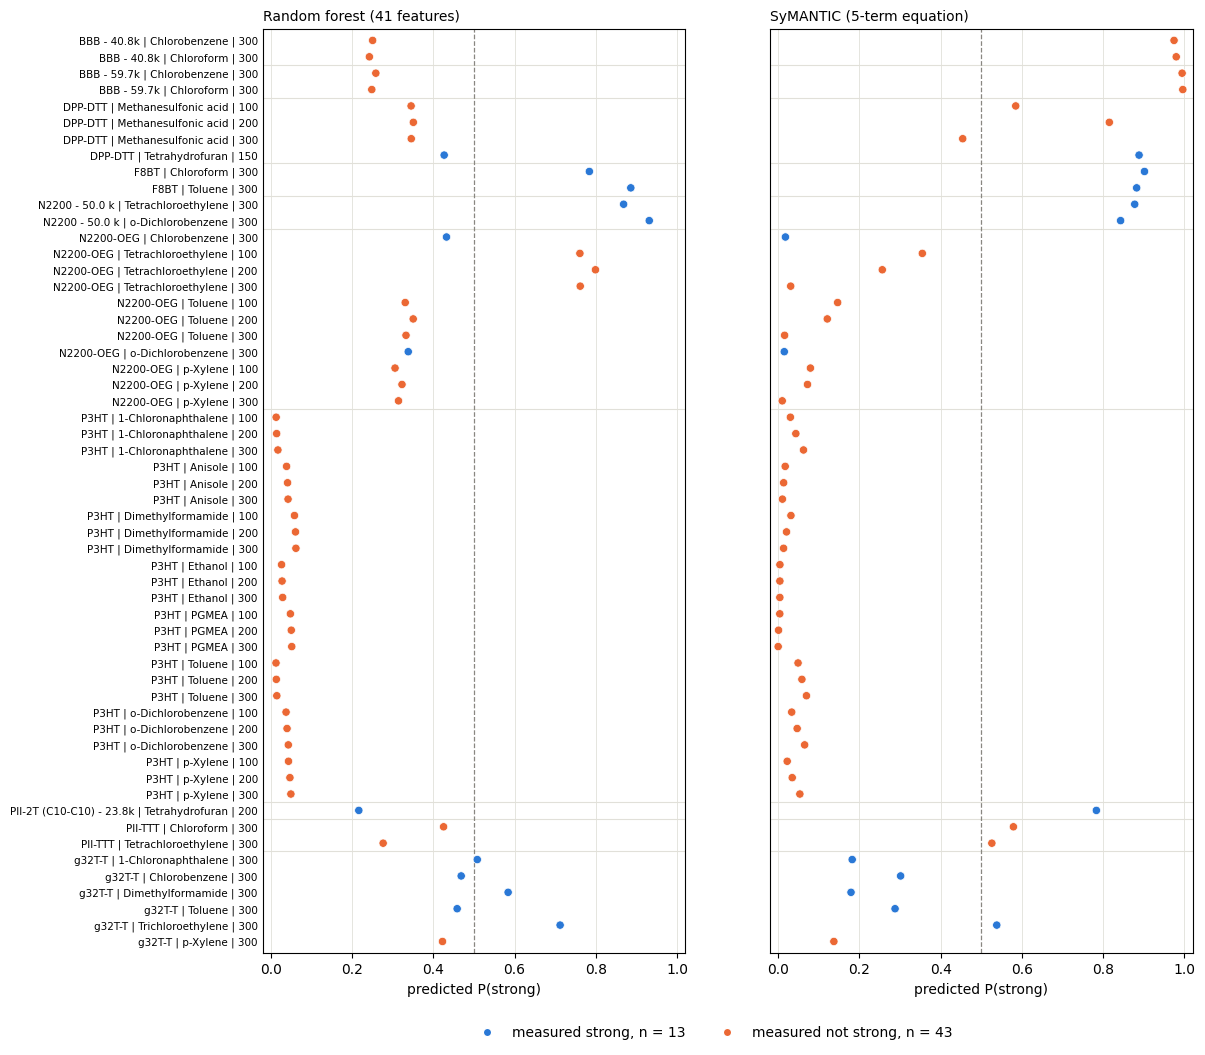

In [7]:
meta56 = d.meta.iloc[test]
order = np.lexsort((d.X['Concentration_mg_mL'].to_numpy()[test], meta56['solvent'].to_numpy(),
                    meta56['polymer'].to_numpy()))
rows = test[order]
names = [f'{p} | {s} | {c:g}' for p, s, c in zip(d.meta['polymer'].to_numpy()[rows], d.meta['solvent'].to_numpy()[rows],
                                                 d.X['Concentration_mg_mL'].to_numpy()[rows])]

fig, axes = plt.subplots(1, 2, figsize=(12, 12), sharey=True)
plots.predictions(axes, names, d.y[rows],
                  {'Random forest (41 features)': probability['Random forest'][rows],
                   'SyMANTIC (5-term equation)': probability['SyMANTIC'][rows]},
                  d.meta['polymer'].to_numpy()[rows])
plt.show()

### Reading the test

- **Both models get the bulk right.** They rank all 24 P3HT rows (never strong) low and the 4 strong F8BT and N2200 50k rows high.
- **Most of SyMANTIC's gap is one polymer.**
  - The ladder polymer BBB (4 rows, never strong) gets P = 0.97–1.00. Mostly this comes from T3 = (HBA + F_mono)·c·Mn, which adds +2.8 to +4.6 to the logit for this high-molecular-weight polymer at 300 mg/mL.
  - Confident false alarms cost the most AP. Without the 4 BBB rows, the two models are nearly tied: AP 0.734 for SyMANTIC against 0.758 for the random forest.
- **Other misses by the equation:**
  - 4 more false strong calls: DPP-DTT in methanesulfonic acid (P 0.58 and 0.82) and PII-TTT (0.53–0.58).
  - Low scores for the glycolated g32T-T (P 0.18–0.54 for its 5 strong rows). The equation has no side-chain-oxygen term.
- **Where the equation is right and the forest is not:**
  - DPP-DTT and PII-2T in tetrahydrofuran (strong): the equation gives 0.89 and 0.78, the forest 0.43 and 0.22.
  - N2200-OEG in tetrachloroethylene (not strong): the forest gives 0.76–0.80, the equation at most 0.36.
- **Both miss** the two strong N2200-OEG rows.

On known polymers in new solvents, the random forest ranks better: −0.329 AP, with a 95% interval that just excludes 0. Every test polymer has training rows in the 717, and the forest can draw on them. The equation has to predict from descriptors alone. Section 6 gives the equation the same knowledge, through one offset per chemistry.

## 6. Chemistry offsets

The equation predicts from descriptors only. When a test polymer has been measured before, as all 10 test polymers have, the data also say how that polymer behaved. An offset lets the equation use that:

$$\text{logit}\,P = b_0 + \sum_k \beta_k z_k + u_{\text{chemistry}}$$

- **What it is.** One intercept shift per chemistry: one repeat unit, with its molecular-weight variants together. A positive u means the chemistry is strong more often than its descriptors predict. The equation's terms are unchanged.
- **How it is fitted.** b₀, the five β and all the u are fitted together on the 717 rows by minimising the log-loss plus ½·λ·Σu².
  - The penalty λ pulls each offset towards 0. A chemistry with few rows can only move a little, because its rows give little evidence against the penalty.
  - Statistically, this is a random-intercept (mixed-effects) logistic regression with u ~ N(0, 1/λ). The fit is the posterior mode.
  - A chemistry absent from the training rows gets u = 0. Here that never happens: every test chemistry occurs in the 717.
- **How λ is chosen.** By cross-validation inside the 717 rows (grouped by polymer ‖ solvent, 3 shuffles of 5 folds): the λ with the lowest held-out log-loss. The 56 rows play no part in the choice.

In [8]:
penalty, inner_loss = laws.choose_penalty(F, d.y, rows717, terms, d.chem, d.groups)
fit_off = laws.fit(F, d.y, rows717, terms, d.chem, penalty=penalty)
print(f'Penalty chosen by inner CV on the 717 rows: {penalty:g} (prior SD of an offset: {1 / np.sqrt(penalty):.2f} logit)')
display(pd.DataFrame({'held-out log-loss': inner_loss}, index=pd.Index(inner_loss, name='penalty')).T.round(4))

print(fit_off.equation())
display(pd.DataFrame({'term': [data.short(t) for t in terms],
                      'effect, equation alone': fit717.effects.round(2),
                      'effect, with offsets': fit_off.effects.round(2)},
                     index=[f'T{k + 1}' for k in range(len(terms))]))

polymer = pd.Series(d.meta['polymer'].to_numpy())
chem_names = polymer.groupby(d.chem).agg(lambda s: ' / '.join(sorted(set(s))))
train = pd.DataFrame({'chem': d.chem[rows717], 'y': d.y[rows717]}).groupby('chem')['y'].agg(['size', 'mean'])
offsets = pd.DataFrame({'polymers': chem_names[np.unique(d.chem[test])]})
offsets['rows in the 717'] = train['size']
offsets['strong share in the 717'] = train['mean'].round(2)
offsets['offset u'] = [round(fit_off.offsets[c], 2) for c in offsets.index]
offsets['test rows'] = pd.Series(d.chem[test]).value_counts()
print(f'{len(fit_off.offsets)} offsets fitted (range {min(fit_off.offsets.values()):+.2f} to '
      f'{max(fit_off.offsets.values()):+.2f}); the chemistries of the test rows:')
with pd.option_context('display.max_colwidth', None):
    display(offsets.sort_values('offset u').reset_index(drop=True))

Penalty chosen by inner CV on the 717 rows: 1 (prior SD of an offset: 1.00 logit)


penalty,0.03,0.10,0.30,1.00,3.00,10.00
held-out log-loss,0.4282,0.409,0.3967,0.3926,0.3943,0.3999


logit P = +0.00134·((SC_C-BB_C)·(c·SC_branch)) +0.2883·((HBA-F_mono)·(SC_units·F_mono)) -1.018e-07·((HBA+F_mono)·(c·Mn)) -1.721e-06·((c·SC_C)·(c·SC_branch)) -0.002081·((SC_C-BB_C)·(SC_units·BB_C)) +0.7373 + u_chemistry


,term,"effect, equation alone","effect, with offsets"
T1,((SC_C-BB_C)·(c·SC_branch)),4.10,4.01
T2,((HBA-F_mono)·(SC_units·F_mono)),1.25,1.66
T3,((HBA+F_mono)·(c·Mn)),-0.86,-0.99
T4,((c·SC_C)·(c·SC_branch)),-2.77,-2.73
T5,((SC_C-BB_C)·(SC_units·BB_C)),-0.94,-1.02


59 offsets fitted (range -1.49 to +2.45); the chemistries of the test rows:


,polymers,rows in the 717,strong share in the 717,offset u,test rows
0,BBB - 40.8k / BBB - 59.7k,4,0.00,-1.28,4
1,PII-TTT,3,0.00,-0.88,2
2,PII-2T (C10-C10) - 18.8k / PII-2T (C10-C10) - 22.8k / PII-2T (C10-C10) - 23.8k,49,0.39,-0.84,1
3,P3HT,9,0.00,-0.35,24
4,DPP-DTT,31,0.77,0.34,4
5,F8BT,4,1.00,0.46,2
6,N2200 - 130.0 k / N2200 - 22.0 k / N2200 - 3.6 k / N2200 - 5.7 k / N2200 - 50.0 k / N2200 - 9.1 k,100,0.60,1.09,2
7,N2200-OEG,6,0.50,1.39,11
8,g32T-T,13,0.54,2.45,6


In [9]:
probability['SyMANTIC + offsets'] = np.full(len(d.y), np.nan)
probability['SyMANTIC + offsets'][test] = fit_off.probability(F[test], d.chem[test])

table, draws_ap = protocol.holdout_table(d, probability, test, d.groups[test])
display(table)
for a, b in [('SyMANTIC + offsets', 'SyMANTIC'), ('SyMANTIC + offsets', 'Random forest')]:
    delta, ci = protocol.paired_difference(d, probability, draws_ap, test, a, b)
    print(f'{a} - {b}: {delta:+.3f} AP, 95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]')

sensitivity = {lam: protocol.ap(d, laws.fit(F, d.y, rows717, terms, d.chem, lam).logit(F, d.chem), test)
               for lam in inner_loss}
print('For reading only (not used to choose the penalty), AP on the 56 at each penalty:',
      ', '.join(f'{lam:g}: {v:.3f}' for lam, v in sensitivity.items()))

,AP,AP 95% CI,AUC,AUC 95% CI,strong rows caught (P > 0.5),not-strong rows called strong,accuracy
SyMANTIC,0.425,"[0.251, 0.718]",0.753,"[0.575, 0.896]",7 of 13,8 of 43,0.75
Random forest,0.754,"[0.483, 1.000]",0.911,"[0.772, 1.000]",7 of 13,3 of 43,0.839
SyMANTIC + offsets,0.504,"[0.315, 0.800]",0.841,"[0.703, 0.946]",10 of 13,7 of 43,0.821


SyMANTIC + offsets - SyMANTIC: +0.079 AP, 95% CI [+0.006, +0.173]
SyMANTIC + offsets - Random forest: -0.250 AP, 95% CI [-0.551, +0.070]
For reading only (not used to choose the penalty), AP on the 56 at each penalty: 0.03: 0.731, 0.1: 0.659, 0.3: 0.562, 1: 0.504, 3: 0.482, 10: 0.439


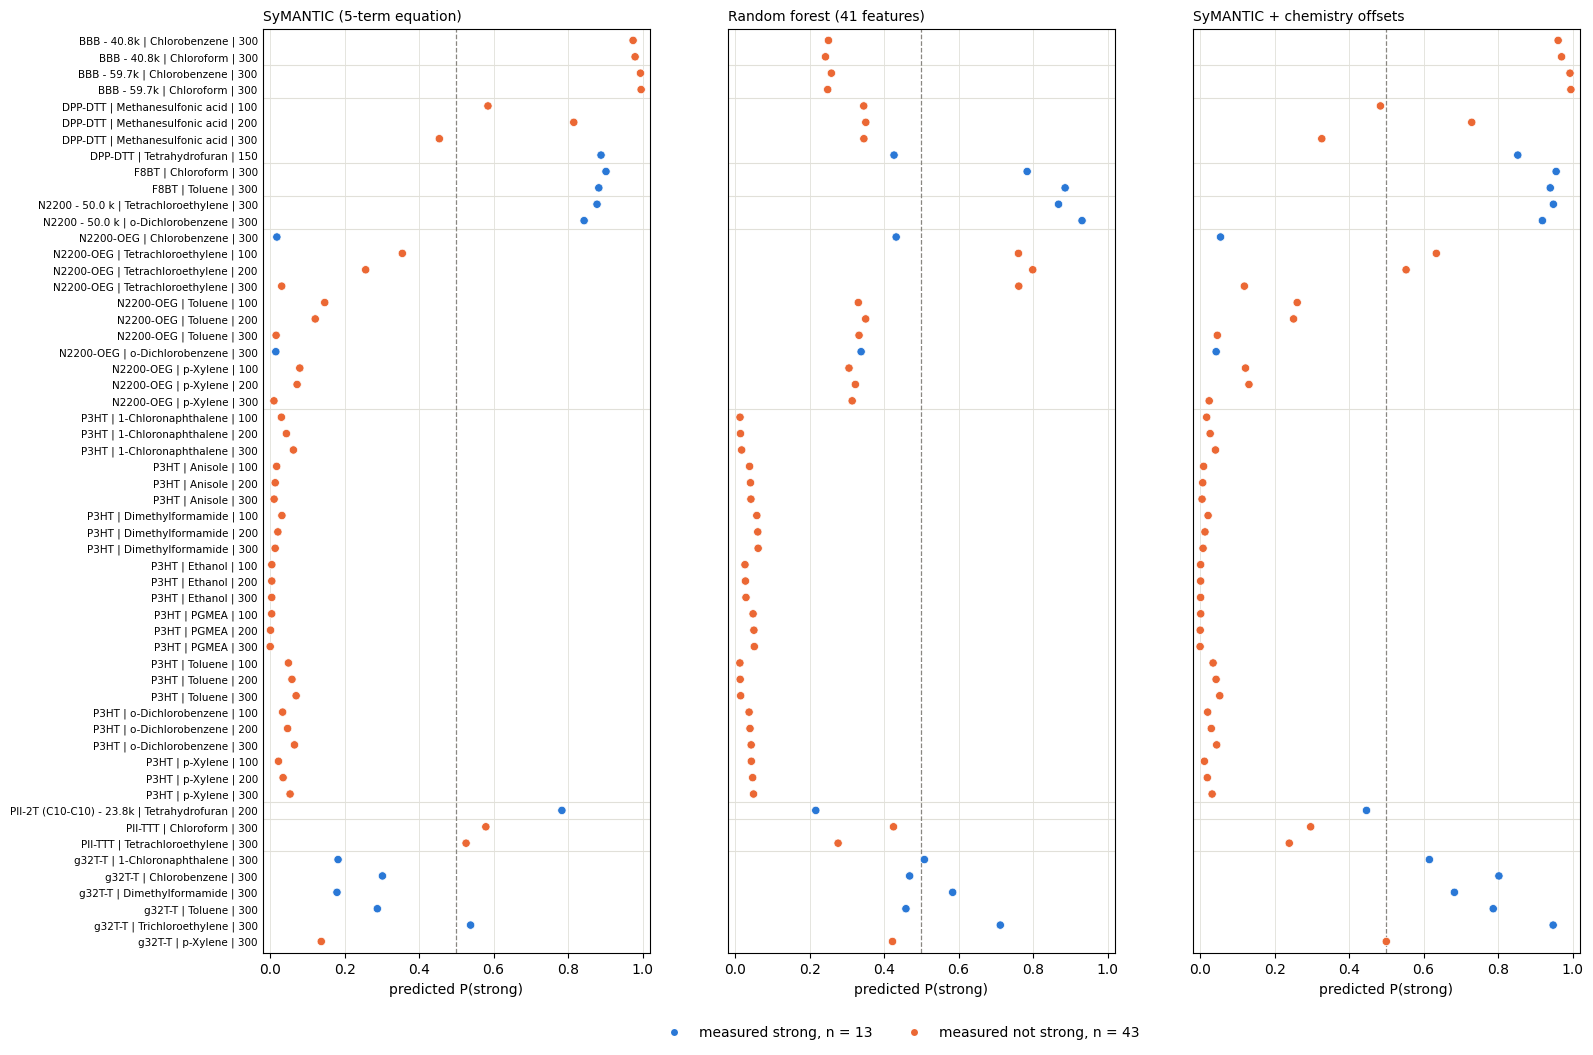

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 12), sharey=True)
plots.predictions(axes, names, d.y[rows],
                  {'SyMANTIC (5-term equation)': probability['SyMANTIC'][rows],
                   'Random forest (41 features)': probability['Random forest'][rows],
                   'SyMANTIC + chemistry offsets': probability['SyMANTIC + offsets'][rows]},
                  d.meta['polymer'].to_numpy()[rows])
plt.show()

### Reading the three panels

Each offset moves all rows of its chemistry by the same amount on the logit scale. The equation still decides the order of rows within a chemistry. The offsets of the test chemistries (table above) run from −1.28 (BBB) to +2.45 (g32T-T).

- **Where the offsets help.** In each case, the polymer's training rows carry information the descriptors lack.
  - g32T-T (u = +2.45; 7 of its 13 training rows strong): its 5 strong rows rise from P 0.18–0.54 to 0.62–0.95. The chemistry's own history covers the glycolated side chain the equation cannot see. Its one not-strong row rises to 0.50, at the threshold.
  - PII-TTT (u = −0.88; never strong in training): its two false strong calls drop from 0.53–0.58 to 0.24–0.30.
  - DPP-DTT in methanesulfonic acid (u = +0.34) falls back to 0.48 at 100 mg/mL. It stays above 0.5 at 200 mg/mL (0.73).
  - F8BT and N2200 50k (strong) rise to 0.92–0.96.
- **Where they cannot help.**
  - BBB stays at P 0.96–1.00. The equation part gives BBB a logit of +4.5 to +6.6 at 300 mg/mL. Its offset is only −1.28, because 4 training rows are little evidence against the penalty.
  - N2200-OEG (u = +1.39; 3 of 6 training rows strong): the offset lifts its not-strong rows in tetrachloroethylene to 0.55–0.63, two new false strong calls. Its two strong rows stay at 0.04–0.05. The equation ranks this chemistry's rows the wrong way round, and a shift cannot reorder them.
  - PII-2T (C10-C10) 23.8k in tetrahydrofuran (strong): its chemistry is strong in 39% of training rows, and u = −0.84 pulls it from 0.78 to 0.45, below the threshold.
- **Net effect.** AP 0.425 → 0.504, a change of +0.079 whose 95% interval [+0.006, +0.173] excludes 0. 10 of 13 strong rows are caught instead of 7. It is still below the random forest: −0.250 [−0.551, +0.070], not significant.
- **The penalty matters.** Inner CV on the 717 rows chose λ = 1, but its held-out log-loss is nearly flat between 0.3 and 3. A weaker penalty lets the offsets grow (at λ = 0.03: g32T-T +5.2, PII-TTT −3.0), and the AP on the 56 would have been higher (0.731), because every test chemistry has training rows. BBB stays above 0.8 at every penalty. Choosing λ by its score on the 56 would be fitting to the test, so λ = 1 is the honest choice.

## 7. The structure found on all 773 rows (B32)

The same search as in section 2, run on all 773 rows, gives the 5-term equation B32. Below, its structure (which terms) is kept fixed, and its coefficients are fitted on the 717 initial rows only. It is then tested on the 56 rows like the 717 equation.

**Caveat:** B32's terms were chosen with the 56 rows included. The coefficients never see them, but the structure did. The results on the 56 are therefore not a clean test of B32. Read them as an upper bound: how well the equation predicts once its terms are already known to suit these rows. The clean test is the 717 equation of sections 5 and 6.

In [11]:
rows773 = d.rows['773']
front773 = search.search(d, rows773, operators='binary')
best773 = front773.loc[front773.groupby('n_terms').log_loss.idxmin()]
print(f'{len(front773)} models on the Pareto front (all 773 rows); the lowest-loss model for each number of terms:')
with pd.option_context('display.max_colwidth', None):
    display(best773.assign(equation=best773.equation.map(data.short)).set_index('n_terms').round(3))

terms32 = search.terms(search.best(front773, k=5)['equation'])
print('Same terms as B32 in chiral_sr/laws.py:', terms32 == laws.LAWS['B32']['terms'])
F32 = laws.term_values(terms32, d.X)
fit32 = laws.fit(F32, d.y, rows717, terms32)                 # structure from 773 rows, coefficients from the 717
print('Coefficients fitted on the 717 rows:')
print(fit32.equation())
display(pd.DataFrame({'term': [data.short(t) for t in terms32], 'effect (logit per SD)': fit32.effects.round(2)},
                     index=[f'T{k + 1}' for k in range(len(terms32))]))

33 models on the Pareto front (all 773 rows); the lowest-loss model for each number of terms:


,complexity,log_loss,equation
n_terms,,,
0,0.000,0.648,logit P(1) = -0.616481
1,1.000,0.566,logit P(1) = 0.94319·SC_branch + -1.79285
2,5.755,0.538,logit P(1) = 0.0227406·(SC_C·SC_branch) + -0.371187·SC_units + -0.776548
3,36.020,0.484,logit P(1) = 0.000573951·((SC_C-BB_C)·(c·SC_branch)) + 0.575285·(HBA·(SC_units·F_bb)) + -0.000990768·(F_bb·(c·F_bb)) + -0.901798
4,52.273,0.445,logit P(1) = 0.00067552·((SC_C-BB_C)·(c·SC_branch)) + 0.589197·(HBA·(SC_units·F_bb)) + 1.5969e-05·(c·(c·F_bb)) + -0.00203031·((SC_C-BB_C)·(SC_units·BB_C)) + 0.1752
5,78.696,0.412,logit P(1) = 0.000920945·((SC_C-BB_C)·(c·SC_branch)) + 0.713484·(HBA·(SC_units·F_bb)) + 7.99826e-05·((c·F_bb)·(c/BB_conj)) + -0.00206754·((SC_C-BB_C)·(SC_units·BB_C)) + 5.02316e-08·((c·Mn)·(BB_C/BB_hetero)) + -0.611887


Same terms as B32 in chiral_sr/laws.py: True
Coefficients fitted on the 717 rows:
logit P = +0.0009784·((SC_C-BB_C)·(c·SC_branch)) +0.6838·(HBA·(SC_units·F_bb)) +9.122e-05·((c·F_bb)·(c/BB_conj)) -0.001954·((SC_C-BB_C)·(SC_units·BB_C)) +5.355e-08·((c·Mn)·(BB_C/BB_hetero)) -0.7212


,term,effect (logit per SD)
T1,((SC_C-BB_C)·(c·SC_branch)),2.92
T2,(HBA·(SC_units·F_bb)),1.24
T3,((c·F_bb)·(c/BB_conj)),1.93
T4,((SC_C-BB_C)·(SC_units·BB_C)),-0.96
T5,((c·Mn)·(BB_C/BB_hetero)),0.75


**B32, the structure found on all 773 rows**, with the coefficients fitted on the 717 rows (printed above):

$$
\begin{aligned}
\operatorname{logit} P \;=\;& 9.784\times10^{-4}\,(\mathrm{SC_C}-\mathrm{BB_C})\;c\;\mathrm{SC_{branch}}
\;+\; 0.6838\;\mathrm{HBA}\;\mathrm{SC_{units}}\;F_{\mathrm{bb}}
\;+\; 9.122\times10^{-5}\,\frac{c^{2}\,F_{\mathrm{bb}}}{\mathrm{BB_{conj}}} \\
&-\; 1.954\times10^{-3}\,(\mathrm{SC_C}-\mathrm{BB_C})\;\mathrm{SC_{units}}\;\mathrm{BB_C}
\;+\; 5.355\times10^{-8}\;c\;M_n\,\frac{\mathrm{BB_C}}{\mathrm{BB_{hetero}}}
\;-\; 0.7212
\end{aligned}
$$

The units are as in section 2. F_bb is the FASTSOLV solubility of the backbone (log₁₀ mol/L). BB_conj and BB_hetero are the backbone's conjugated units and heteroatoms per mass (mol/kg). The coefficients of the search's own fit on all 773 rows are in the 5-term line of the Pareto table above.

### Reading B32 (semi-quantitative)

Effects are per SD, fitted on the 717 rows. Two of B32's terms are identical to the 717 equation's: T1 here is T1 there, and T4 here is T5 there. The other three play the same roles, but with **backbone** solubility (F_bb) where the 717 equation used repeat-unit solubility.

- **T1: side chains × concentration (+2.92).** (SC_C − BB_C)·c·SC_branch, the same main term as before.
- **T3: concentration cap set by the backbone (+1.93).** c²·F_bb/BB_conj.
  - F_bb (log₁₀ solubility of the backbone) is negative for 95% of rows, so T3 is negative. It grows with c², more for backbones that dissolve poorly.
  - With T1, the concentration effect for branched, carbon-rich side chains peaks at a median of about 190 mg/mL (half of these rows between 174 and 246 mg/mL).
  - The 717 equation built its cap from side-chain carbon. Here it comes from backbone solubility, which reads naturally as poorly soluble backbones aggregating at high concentration.
  - T3 and T1 are correlated (r = −0.55), so they are read together.
- **T2: H-bond-acceptor solvents (+1.24).** HBA·SC_units·F_bb is non-zero only in solvents with H-bond acceptors (196 of the 717 rows). With F_bb < 0 it lowers P there, more so for polymers with many side chains and poorly soluble backbones.
- **T4: polymer baseline (−0.96).** (SC_C − BB_C)·SC_units·BB_C, as in the 717 equation. Carbon-rich side chains start lower in dilute solution.
- **T5: chain length × concentration (+0.75).** c·Mn·BB_C/BB_hetero. Long chains at high concentration raise P, more so for carbon-rich backbones (BB_C/BB_hetero runs from 2.1 to 6.3).

In the law plane below, x is now T1 + T3 + T5 (the terms with c), and y is the intercept + T2 + T4.

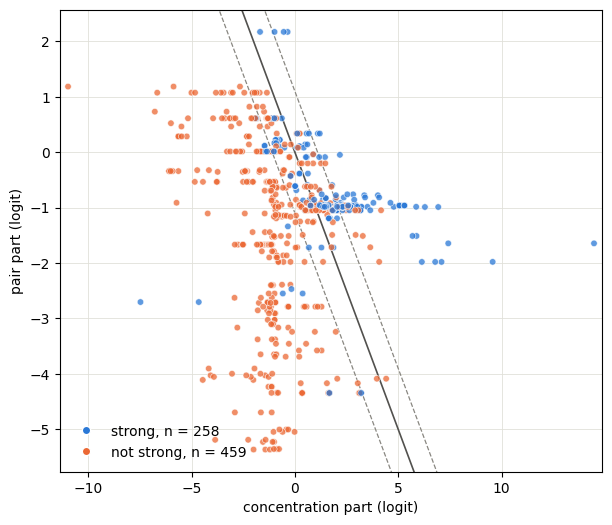

In [12]:
x32, pair32 = laws.law_plane(fit32, F32[rows717])
fig, ax = plt.subplots(figsize=(7, 6))
plots.law_plane(ax, x32, pair32, d.y[rows717])
plt.show()

In [13]:
prob32 = {'B32': np.full(len(d.y), np.nan), 'Random forest': probability['Random forest']}
prob32['B32'][test] = fit32.probability(F32[test])

table32, draws32 = protocol.holdout_table(d, prob32, test, d.groups[test])
display(table32)
delta, ci = protocol.paired_difference(d, prob32, draws32, test, 'B32', 'Random forest')
print(f'B32 - random forest: {delta:+.3f} AP, 95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]')

,AP,AP 95% CI,AUC,AUC 95% CI,strong rows caught (P > 0.5),not-strong rows called strong,accuracy
B32,0.734,"[0.496, 0.944]",0.85,"[0.693, 0.973]",8 of 13,1 of 43,0.893
Random forest,0.754,"[0.483, 1.000]",0.911,"[0.772, 1.000]",7 of 13,3 of 43,0.839


B32 - random forest: -0.020 AP, 95% CI [-0.341, +0.248]


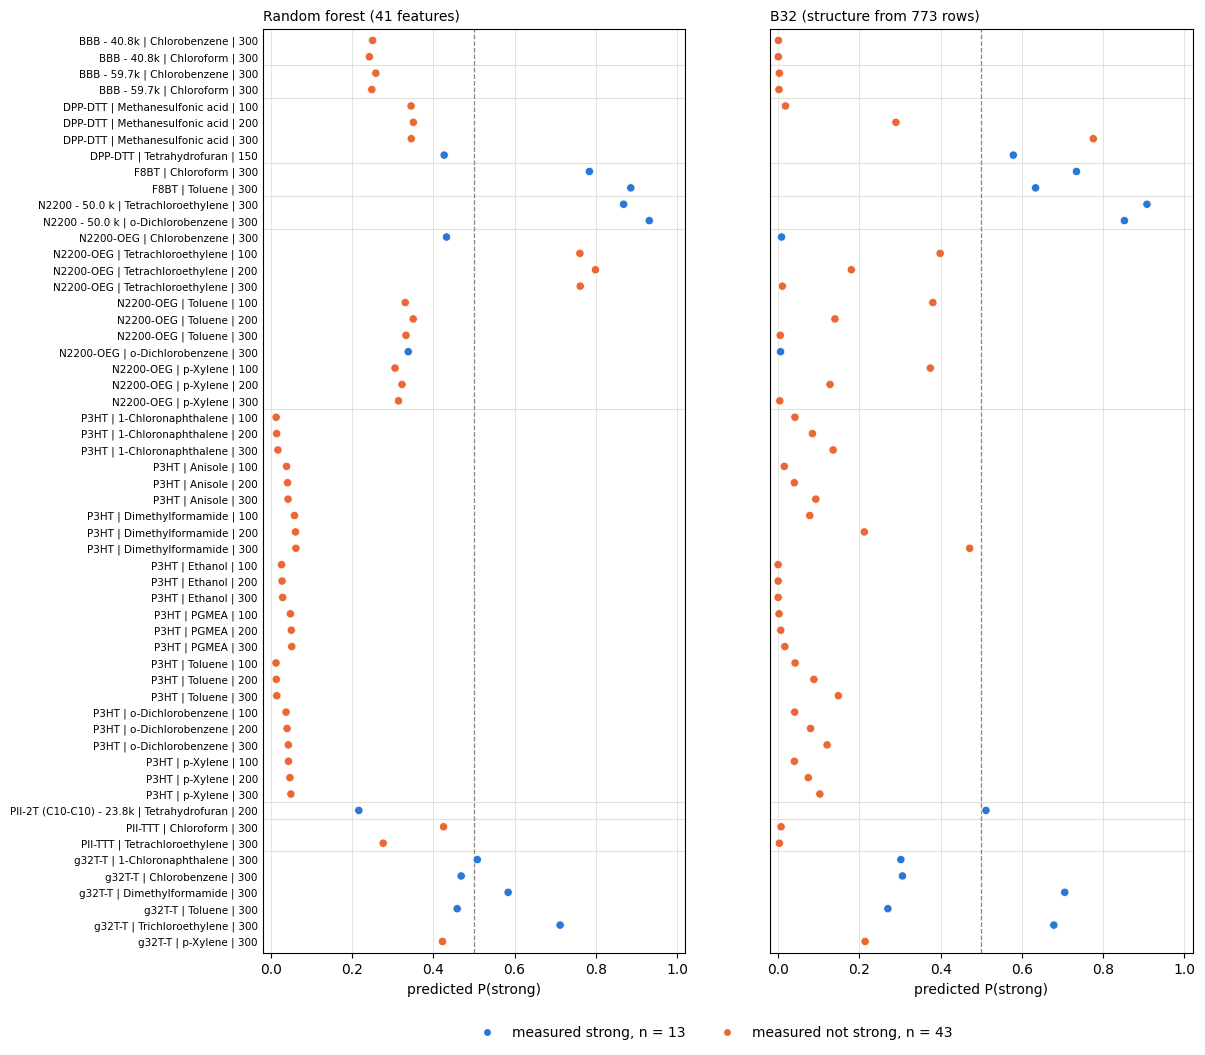

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 12), sharey=True)
plots.predictions(axes, names, d.y[rows],
                  {'Random forest (41 features)': prob32['Random forest'][rows],
                   'B32 (structure from 773 rows)': prob32['B32'][rows]},
                  d.meta['polymer'].to_numpy()[rows])
plt.show()

### Reading the test (B32)

- **B32 ties the random forest on the 56.** AP 0.734 against 0.754, a difference of −0.020 [−0.341, +0.248]. It catches 8 of the 13 strong rows and makes 1 false strong call, against 7 and 3 for the forest.
- **The gain over the 717 equation (0.425) is mostly BBB.**
  - B32 gives the 4 BBB rows P = 0.00. Its concentration cap T3 = c²·F_bb/BB_conj contributes −7.3 to −7.6 there: BBB's backbone barely dissolves.
  - The 717 equation, whose search did not include these rows, called BBB 0.97–1.00.
  - Whether a search without the 56 rows would also find T3 is exactly what this test cannot tell. The 717 search did not. The gap between the two equations therefore measures what having the 56 rows in the structure search was worth on this split.
- **What B32 still misses:**
  - 3 of the 5 strong g32T-T rows (P 0.27–0.31) and both strong N2200-OEG rows (0.01). These are the glycolated polymers; B32 has no side-chain-oxygen term either.
  - One false strong call: DPP-DTT in methanesulfonic acid at 300 mg/mL (0.78).
  - P3HT stays below 0.5 everywhere, up to 0.47 in dimethylformamide at 300 mg/mL.

## 8. B32 + chemistry offsets

The same procedure as in section 6. B32's terms are fixed, and its coefficients and one offset per chemistry are fitted together on the 717 rows. The penalty is chosen by inner cross-validation on the 717 rows. The caveat of section 7 still applies.

In [15]:
penalty32, inner_loss32 = laws.choose_penalty(F32, d.y, rows717, terms32, d.chem, d.groups)
fit32_off = laws.fit(F32, d.y, rows717, terms32, d.chem, penalty=penalty32)
print(f'Penalty chosen by inner CV on the 717 rows: {penalty32:g} (prior SD of an offset: {1 / np.sqrt(penalty32):.2f} logit)')
display(pd.DataFrame({'held-out log-loss': inner_loss32}, index=pd.Index(inner_loss32, name='penalty')).T.round(4))

print(fit32_off.equation())
display(pd.DataFrame({'term': [data.short(t) for t in terms32],
                      'effect, B32 alone': fit32.effects.round(2),
                      'effect, with offsets': fit32_off.effects.round(2)},
                     index=[f'T{k + 1}' for k in range(len(terms32))]))
offsets32 = offsets[['polymers', 'rows in the 717', 'strong share in the 717', 'test rows']].copy()
offsets32.insert(3, 'offset u', [round(fit32_off.offsets[c], 2) for c in offsets.index])
with pd.option_context('display.max_colwidth', None):
    display(offsets32.sort_values('offset u').reset_index(drop=True))

Penalty chosen by inner CV on the 717 rows: 1 (prior SD of an offset: 1.00 logit)


penalty,0.03,0.10,0.30,1.00,3.00,10.00
held-out log-loss,0.4874,0.456,0.4348,0.4247,0.4248,0.4303


logit P = +0.0009257·((SC_C-BB_C)·(c·SC_branch)) +0.7184·(HBA·(SC_units·F_bb)) +8.586e-05·((c·F_bb)·(c/BB_conj)) -0.001929·((SC_C-BB_C)·(SC_units·BB_C)) +6.233e-08·((c·Mn)·(BB_C/BB_hetero)) -0.9453 + u_chemistry


,term,"effect, B32 alone","effect, with offsets"
T1,((SC_C-BB_C)·(c·SC_branch)),2.92,2.77
T2,(HBA·(SC_units·F_bb)),1.24,1.31
T3,((c·F_bb)·(c/BB_conj)),1.93,1.82
T4,((SC_C-BB_C)·(SC_units·BB_C)),-0.96,-0.95
T5,((c·Mn)·(BB_C/BB_hetero)),0.75,0.87


,polymers,rows in the 717,strong share in the 717,offset u,test rows
0,PII-2T (C10-C10) - 18.8k / PII-2T (C10-C10) - 22.8k / PII-2T (C10-C10) - 23.8k,49,0.39,-0.74,1
1,P3HT,9,0.00,-0.64,24
2,BBB - 40.8k / BBB - 59.7k,4,0.00,-0.56,4
3,PII-TTT,3,0.00,-0.37,2
4,F8BT,4,1.00,0.43,2
5,N2200 - 130.0 k / N2200 - 22.0 k / N2200 - 3.6 k / N2200 - 5.7 k / N2200 - 50.0 k / N2200 - 9.1 k,100,0.60,0.49,2
6,DPP-DTT,31,0.77,0.49,4
7,N2200-OEG,6,0.50,1.50,11
8,g32T-T,13,0.54,1.63,6


In [16]:
prob32['B32 + offsets'] = np.full(len(d.y), np.nan)
prob32['B32 + offsets'][test] = fit32_off.probability(F32[test], d.chem[test])

table32, draws32 = protocol.holdout_table(d, prob32, test, d.groups[test])
display(table32)
for a, b in [('B32 + offsets', 'B32'), ('B32 + offsets', 'Random forest')]:
    delta, ci = protocol.paired_difference(d, prob32, draws32, test, a, b)
    print(f'{a} - {b}: {delta:+.3f} AP, 95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]')

sensitivity32 = {lam: protocol.ap(d, laws.fit(F32, d.y, rows717, terms32, d.chem, lam).logit(F32, d.chem), test)
                 for lam in inner_loss32}
print('For reading only (not used to choose the penalty), AP on the 56 at each penalty:',
      ', '.join(f'{lam:g}: {v:.3f}' for lam, v in sensitivity32.items()))

,AP,AP 95% CI,AUC,AUC 95% CI,strong rows caught (P > 0.5),not-strong rows called strong,accuracy
B32,0.734,"[0.496, 0.944]",0.85,"[0.693, 0.973]",8 of 13,1 of 43,0.893
Random forest,0.754,"[0.483, 1.000]",0.911,"[0.772, 1.000]",7 of 13,3 of 43,0.839
B32 + offsets,0.805,"[0.598, 0.959]",0.891,"[0.771, 0.981]",10 of 13,6 of 43,0.839


B32 + offsets - B32: +0.071 AP, 95% CI [-0.076, +0.203]
B32 + offsets - Random forest: +0.051 AP, 95% CI [-0.222, +0.264]
For reading only (not used to choose the penalty), AP on the 56 at each penalty: 0.03: 0.851, 0.1: 0.838, 0.3: 0.836, 1: 0.805, 3: 0.816, 10: 0.751


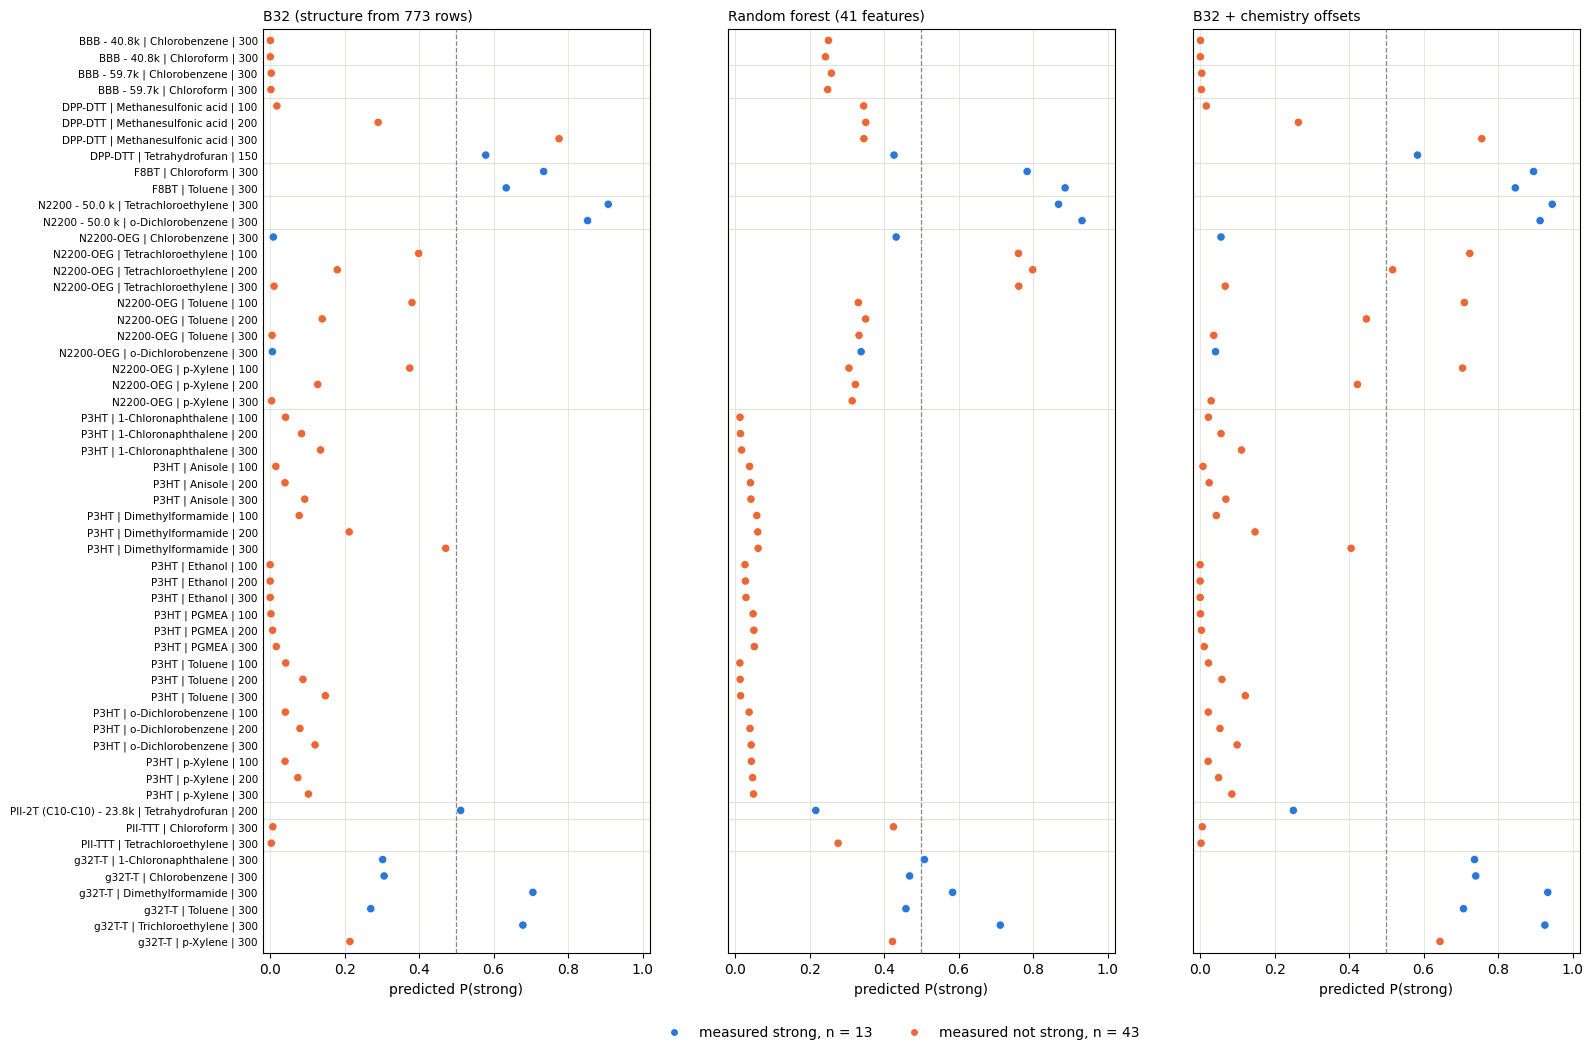

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 12), sharey=True)
plots.predictions(axes, names, d.y[rows],
                  {'B32 (structure from 773 rows)': prob32['B32'][rows],
                   'Random forest (41 features)': prob32['Random forest'][rows],
                   'B32 + chemistry offsets': prob32['B32 + offsets'][rows]},
                  d.meta['polymer'].to_numpy()[rows])
plt.show()

### Reading the three panels (B32)

Inner CV on the 717 rows chose λ = 1, essentially tied with λ = 3 (held-out log-loss 0.4247 and 0.4248). The offsets of the test chemistries run from −0.74 (PII-2T C10-C10) to +1.63 (g32T-T). Each moves all rows of its chemistry by the same amount.

- **Where the offsets help.**
  - g32T-T (u = +1.63): all 5 strong rows are now above 0.5 (0.71–0.93), up from 2 of 5. This is the same rescue as for the 717 equation: the chemistry's own history covers the glycolated side chain.
  - F8BT and N2200 50k rise to 0.85–0.95.
- **Where they hurt or cannot help.**
  - N2200-OEG (u = +1.50): its not-strong rows at 100 mg/mL rise to 0.70–0.72, and in tetrachloroethylene at 200 mg/mL to 0.52. That is four new false strong calls. Its two strong rows stay at 0.04–0.06: the equation orders this chemistry's rows the wrong way round, and a shift cannot reorder them.
  - g32T-T's one not-strong row rises to 0.64.
  - PII-2T (C10-C10) 23.8k in tetrahydrofuran (strong) drops from 0.51 to 0.25 (u = −0.74).
  - BBB (0.00), PII-TTT (0.00–0.01) and DPP-DTT in methanesulfonic acid at 300 mg/mL (0.76) are unchanged.
- **Net effect.** AP 0.734 → 0.805: +0.071 [−0.076, +0.203], not significant. 10 of 13 strong rows are caught and 6 not-strong rows are called strong. Against the random forest the difference is +0.051 [−0.222, +0.264].
- **Penalty.** A weaker penalty would score up to 0.851 on the 56, and λ = 10 would score 0.751. As in section 6, the 56 cannot be used to choose it.

As section 7 explains, these numbers are an upper bound: B32's terms were chosen with the 56 rows in view. "B32 + offsets above the random forest" is therefore not a claim this split can support. The honest comparison is the 717 equation, with and without offsets (sections 5 and 6).